<a href="https://colab.research.google.com/github/MauricioTurdo/Aprendizaje_Automatico/blob/main/Clase%208/Untitled0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clase 8 Aprendizaje Automatico
## Instancia de Autoevaluación

 Aprendizaje No Supervisado utilizando K-Means

 Objetivo: identificar cuántos segmentos latentes de clientes existen a partir de sus comportamientos de compra y uso del sitio, sin etiquetas previas.

### Variables Predictoras

1. purchase_freq_month — frecuencia de compras por mes (escala baja a media).

2. avg_basket_usd — ticket/promedio por compra en USD (escala media a alta).

3. time_on_site_min — tiempo de permanencia en el sitio (minutos).

4. discount_sensitivity — sensibilidad a descuentos (0 a 1).

5. returns_rate — tasa de devoluciones (0 a 0.8 aprox.).


### Qué patrones buscar:

Grupos con frecuencia alta pero ticket bajo y alta sensibilidad a descuentos.

Grupos con frecuencia baja pero ticket alto y baja sensibilidad (compras esporádicas pero grandes).

Grupos con tiempo en sitio y tasa de devoluciones diferenciados (p. ej., exploran mucho y devuelven más vs. exploran poco y devuelven menos).

## 1. Importación de librerías

In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score

import warnings
warnings.filterwarnings('ignore')


## 2. Carga y exploración del dataset


In [10]:

df = pd.read_csv("/content/dataset_segmentacion_clientes.csv")
display(df.head())
df.info()
df.describe()
print("Valores nulos por columna:")
print(df.isnull().sum())


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform
0,11.152508,181.300834,33.564036,1.000000,0.800000,-1.806578,-2.516905
1,12.053451,178.637272,35.432081,0.784974,0.000000,0.645129,2.115460
2,2.203006,450.185298,7.030757,0.898297,0.000000,-0.047406,-0.724173
3,4.233314,89.006342,10.834453,0.000000,0.800000,0.901700,-2.974026
4,1.716799,449.773982,7.254548,0.000000,0.003279,0.386013,2.424522


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   purchase_freq_month   700 non-null    float64
 1   avg_basket_usd        700 non-null    float64
 2   time_on_site_min      700 non-null    float64
 3   discount_sensitivity  700 non-null    float64
 4   returns_rate          700 non-null    float64
 5   noise_gauss           700 non-null    float64
 6   noise_uniform         700 non-null    float64
dtypes: float64(7)
memory usage: 38.4 KB
Valores nulos por columna:
purchase_freq_month     0
avg_basket_usd          0
time_on_site_min        0
discount_sensitivity    0
returns_rate            0
noise_gauss             0
noise_uniform           0
dtype: int64


El dataset contiene 700 registros/clientes y 7 columnas, No contiene valores nulos.
Trabajaremos con el dataset disponible en campus el cual contiene los siguientes datos sobre clientes:

1.purchase_freq_month — frecuencia de compras por mes (escala baja a media).

2.avg_basket_usd — ticket/promedio por compra en USD (escala media a alta).

3.time_on_site_min — tiempo de permanencia en el sitio (minutos).

4.discount_sensitivity — sensibilidad a descuentos (0 a 1).

5.returns_rate — tasa de devoluciones (0 a 0.8 aprox.).

Las columnas noise_gauss y noise_uniform las

---

eliminamos segun indicaciones de la actividad.

## . Visualización de los datos


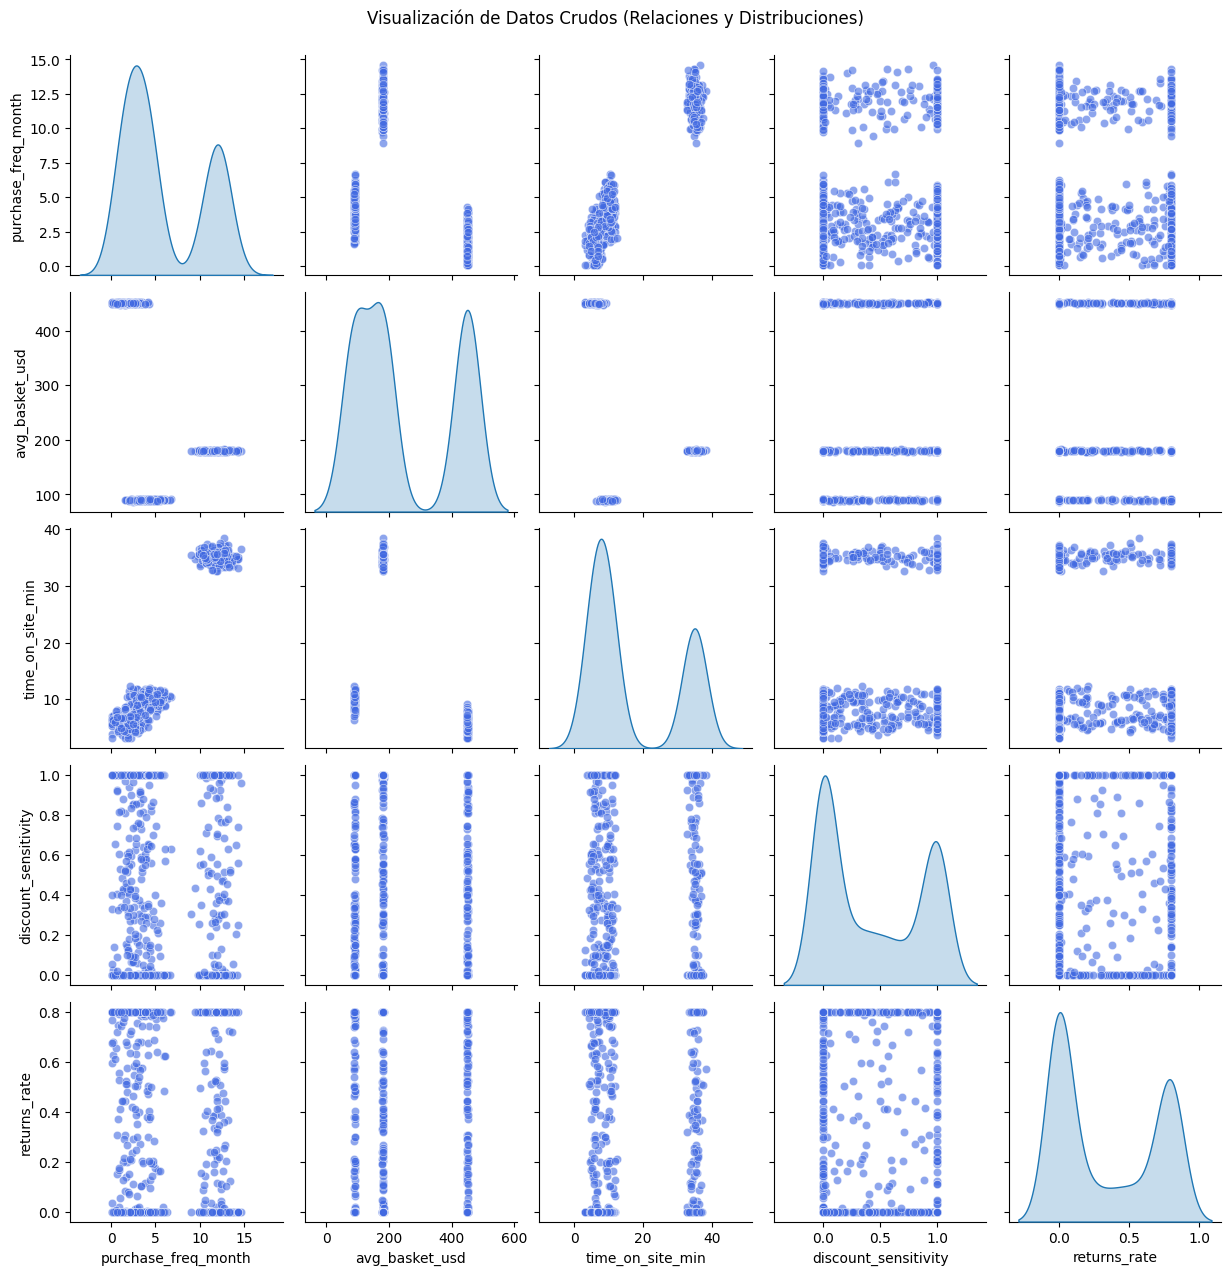

In [11]:
variables_crudas = [
    'purchase_freq_month',
    'avg_basket_usd',
    'time_on_site_min',
    'discount_sensitivity',
    'returns_rate'
]

# Generar el gráfico de pares para ver los datos crudos
sns.pairplot(df[variables_crudas], diag_kind='kde', plot_kws={'alpha': 0.6, 'color': 'royalblue'})
plt.suptitle("Visualización de Datos Crudos (Relaciones y Distribuciones)", y=1.02)
plt.show()
plt.show()

## 3. Verificacion de correlación de Variables

Matriz de Correlación:


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
purchase_freq_month,1.000000,-0.488868,0.967234,0.190964,-0.020488
avg_basket_usd,-0.488868,1.000000,-0.426025,-0.077487,0.086050
time_on_site_min,0.967234,-0.426025,1.000000,0.188449,-0.013936
discount_sensitivity,0.190964,-0.077487,0.188449,1.000000,-0.014467
returns_rate,-0.020488,0.086050,-0.013936,-0.014467,1.000000


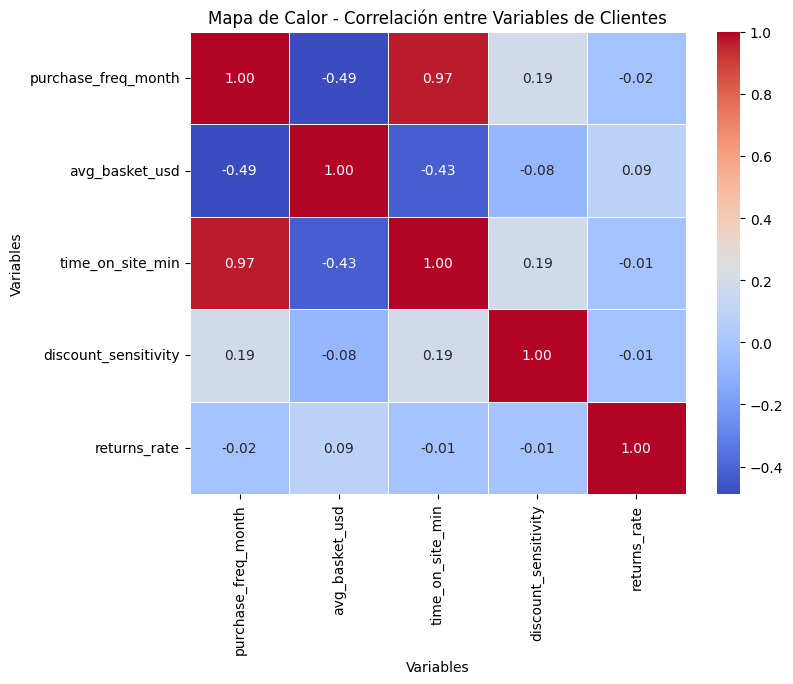

In [12]:
matriz_corr = df[['purchase_freq_month', 'avg_basket_usd', 'time_on_site_min', 'discount_sensitivity', 'returns_rate']].corr()

print("Matriz de Correlación:")
display(matriz_corr)

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Mapa de Calor - Correlación entre Variables de Clientes')
plt.xlabel('Variables')
plt.ylabel('Variables')
plt.show()



## Analisis de la Correlacion:



*   Alta relación entre Frecuencia y Tiempo en el sitio (0.97): Existe una correlación positiva. Los clientes que pasan más tiempo navegando en la plataforma son los que realizan una mayor cantidad de compras mensuales.
*   Relación inversa con el Ticket Promedio (-0.49 y -0.43): Los usuarios con mayor frecuencia de compra o mayor permanencia tienden a gastar un importe menor por cada compra individual (compras recurrentes pero pequeñas), lo que contrasta con los compradores esporádicos de tickets más altos.
*   Independencia de Descuentos y Devoluciones: Las variables de sensibilidad
descuentos (discount_sensitivity) y tasa de devoluciones (returns_rate) muestran valores cercanos a 0 frente a las demás. Esto indica que actúan de forma independiente, aportando dimensiones de comportamiento únicas.   

## 4. Selección de variables y escalado

Nota: K-Means usa distancias euclidianas, por lo que es imprescindible escalar las variables.

In [13]:

X = df[['purchase_freq_month', 'avg_basket_usd', 'time_on_site_min', 'discount_sensitivity', 'returns_rate']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
print("Datos escalados (primeras 5 filas):")
display(X_scaled_df.head())

Datos escalados (primeras 5 filas):


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
0,1.181048,-0.432012,1.300224,1.333423,1.298671
1,1.382696,-0.449219,1.444979,0.834706,-0.946196
2,-0.822026,1.305039,-0.755841,1.097540,-0.946196
3,-0.367604,-1.028253,-0.461093,-0.985910,1.298671
4,-0.930849,1.302382,-0.738500,-0.985910,-0.936996


## 5. Distribución de las variables

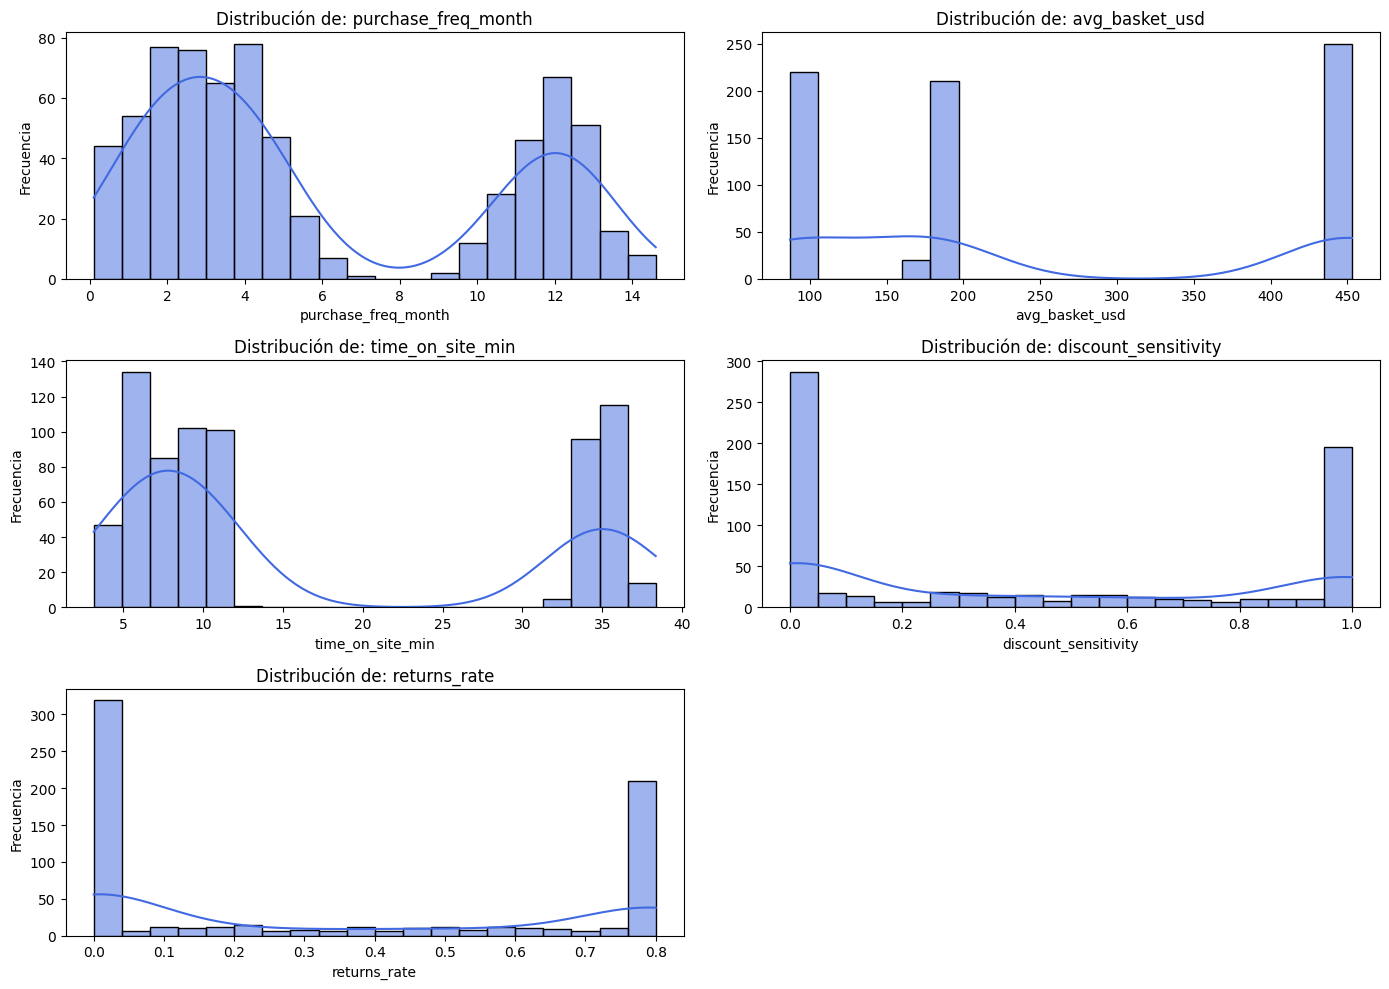

In [14]:
variables_cliente = [
    'purchase_freq_month',
    'avg_basket_usd',
    'time_on_site_min',
    'discount_sensitivity',
    'returns_rate'
]
plt.figure(figsize=(14, 10))

for i, columna in enumerate(variables_cliente, 1):
    plt.subplot(3, 2, i)
    # Histograma con curva de densidad (KDE)
    sns.histplot(df[columna], kde=True, bins=20, color='royalblue')
    plt.title(f'Distribución de: {columna}')
    plt.xlabel(columna)
    plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

*   purchase_freq_month (Frecuencia de compra): Se divide en dos grupos; clientes que compran poco al mes (2 a 4 veces) y clientes muy frecuentes (unos 12 al mes).
*   avg_basket_usd (Ticket promedio): Los clientes se dividen en tres perfiles: los que gastan poco (100 USD), un grupo medio (200 USD) y los que realizan compras grandes (450 USD).
*   time_on_site_min (Tiempo en el sitio): Dos comportamientos marcados: usuarios que navegan poco tiempo (5 a 10 min) frente a usuarios muy exploradores (33 a 37 min).
*   discount_sensitivity (Sensibilidad a descuentos): Está polarizada. O al cliente no le importan nada los descuentos o le interesan al máximo (cerca de 1).
*   returns_rate (Tasa de devoluciones): Dos extremos claros: la gran mayoría casi no devuelve productos (cerca de 0), mientras que un grupo importante registra tasas de devolución muy altas.   




## 6. Busquda de valor de k Optimo usando métricas distintas:

* Método del Codo
* Sihouette Score

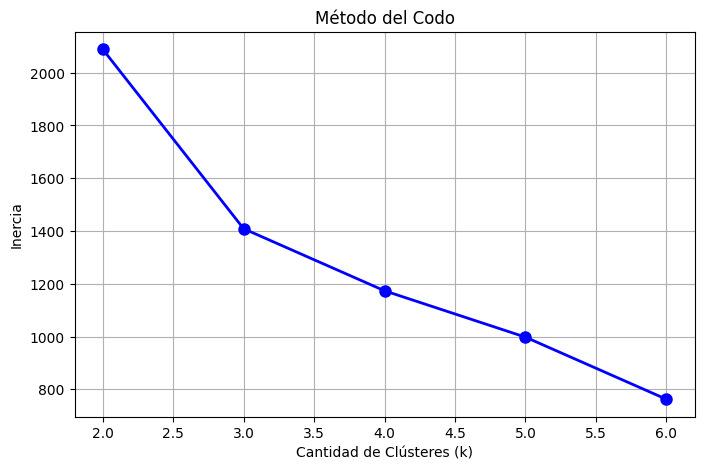

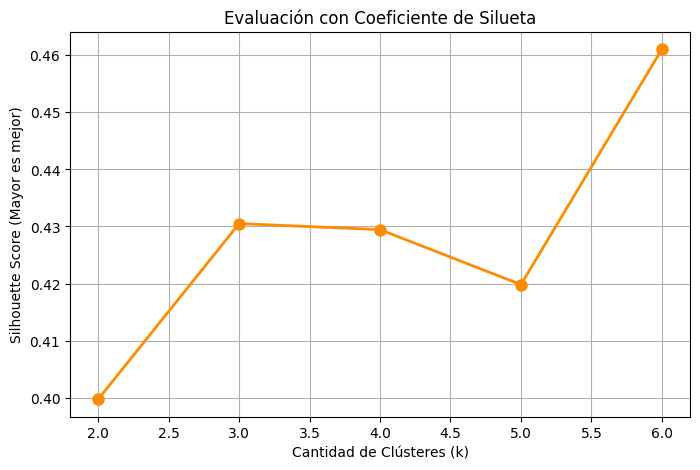

In [15]:
inercias = []
rango_k = range(2, 7)

for k in rango_k:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    inercias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(rango_k, inercias, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
plt.title('Método del Codo')
plt.xlabel('Cantidad de Clústeres (k)')
plt.ylabel('Inercia')
plt.grid(True)
plt.show()

silhouette_scores = []
valores_k_sil = range(2, 7) # Rango de k de 2 a 6

for k in valores_k_sil:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # ¡Esto es lo que faltaba agregar dentro del bucle!
    labels = modelo.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

# Gráfico del Coeficiente de Silueta
plt.figure(figsize=(8, 5))
plt.plot(valores_k_sil, silhouette_scores, marker='o', linestyle='-', color='darkorange', linewidth=2, markersize=8)
plt.title('Evaluación con Coeficiente de Silueta')
plt.xlabel('Cantidad de Clústeres (k)')
plt.ylabel('Silhouette Score (Mayor es mejor)')
plt.grid(True)
plt.show()



### Justificación del K Óptimo
Al analizar la gráfica del Método del Codo para k entre 2 y 6, observamos que el valor de k donde se produce el quiebre mas significativo es en k = 3. Por lo tanto, segun este meotodo el K óptimo de clústeres que podriamos elegiremos para entrenar este modelo es K = 3, ya que a partir de este punto la inercia comienza a disminuir de forma mucho más suave.
 teniendo en cuenta la Inercia podemos saber qué tan compactos son los grupos. Cuanto más baja, mejor,

Si analizamos Silhouette este mide la separación entre los .grupos Sus valores van de -1 a 1, y cuanto más alto sea el número, mejor están definidos los clústeres. para este caso obtenemos un puntaje sólido de 0.4305, lo que demuestra que los tres grupos están bien diferenciados y son coherentes. Tambien podria ser k = 6 la métrica sube un poco más a 0.4610, pero para nuestro problema elegir k = 3 es la mejor decisión ya que nos muestra tres perfiles de clientes claros, fáciles de entender y muy útiles para aplicar estrategias comerciales reales, evitando complicarte con demasiados grupos pequeños.   

## 7. Entrenamiento del modelo final (k=3)

In [21]:
kmeans_final = KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=42)
kmeans_final.fit(X_scaled)

df['Cluster'] = kmeans_final.labels_

print(f"Inercia final (k=3): {kmeans_final.inertia_:.2f}")
print(f"Silhouette Score:{silhouette_score(X_scaled, kmeans_final.labels_):.4f}")

print("Cantidad de clientes por clúster:")
conteo_clusters = df['Cluster'].value_counts().sort_index()
print(conteo_clusters)

Inercia final (k=3): 1408.70
Silhouette Score:0.4305
Cantidad de clientes por clúster:
Cluster
0    230
1    250
2    220
Name: count, dtype: int64


El entrenamiento final segmentó a los 700 clientes en 3 clusters. Las métricas muestran una buena calidad de agrupamiento, con clusters bien separados.

## 8. Análisis de centroides — Perfiles de cada segmento

In [17]:
perfiles_clientes = df.groupby('Cluster')[[
    'purchase_freq_month',
    'avg_basket_usd',
    'time_on_site_min',
    'discount_sensitivity',
    'returns_rate'
]].mean()

print("Centroides (Promedios por Clúster):")
display(perfiles_clientes.round(2))

Centroides (Promedios por Clúster):


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
Cluster,,,,,
0,11.96,180.00,35.02,0.54,0.33
1,1.85,450.12,5.97,0.36,0.38
2,4.09,89.96,10.00,0.38,0.30


A partir de los centroides analizados, identificamos tres perfiles bien diferenciados:

Clúster 1 (Compradores Frecuentes / Sensibles a Ofertas):
   * Caracterizados por una alta frecuencia de compra mensual y mayor tiempo en el sitio, acompañados de un ticket promedio bajo y una alta sensibilidad a los descuentos.
   * Estrategia: campañas de marketing basadas en cupones y promociones masivas .

Clúster 2 (Compradores Esporádicos de Alto Valor / Premium):
   * Presentan una frecuencia de compra baja, pero se destacan por tener el ticket promedio en dólares más elevado y baja sensibilidad a las ofertas.
   * Estrategia: Enfoque en estrategias de productos exclusivos o de gama alta.

Clúster 3 (Exploradores / Perfil de Devoluciones):
   * Agrupa a los usuarios con un comportamiento de navegación particular, marcados por diferencias en su tiempo de permanencia y su tasa de devoluciones respecto al resto.
   * Estrategia: Optimización de la experiencia de usuario en la plataforma y revisión de políticas de devoluciones para este segmento específico.